In [5]:
# Jupyter notebooks allow you to run command-line commands from within a cell by starting with an !. 
# this command runs a python script which sets up the fake data you will practice with take a look 
# at that script after completing this notebook if you'd like and let me know if you'd like more 
# of an explanation
!python ./Fields-prep.py

# Fields
---

Many simulations work by calculating values on a grid of points, representing different places in space and time. For example, the code dHybridR is a particle-in-cell plasma physics simulation. It works by setting up an even grid in space,
$$\frac{x}{dx} = {0, 1, 2, 3, ..., N_x-1},$$
where $x$ is a cartesian coordinate or direction, $dx$ is the distance between grid points, and $N_x$ is the total number of grid points in the $x$ direction.

Say that we have a 2D simulation, with $x$ and $y$ coordinates, dHybridR will calculate the number density of particles in each $dx\times dy$ square, $n = \frac{N}{dxdy}$ where $N$ is the total number of particles-in-that-cell. At each time-step dHybridR will produce and save an array that tells you what the number density at that grid point is.

## $\texttt{ScalarField}$
---

### 1. initialization

One of the most basic uses of this package is to efficiently and intuitively interact with these data products. Say there is a directory filled with the density data from dHybridR:

Then we can get at this data in $\texttt{kgsim}$ with the following code

In [7]:
density_directory: str = "./simulation/outputs/density" # define the location of the density data

from kgsim import ScalarField
density = ScalarField(density_directory)

TypeError: There is no directory at './simulation/outputs/density'

> Uh Oh! that didn't load right, did it? Can you figure out why? Use the code cell below to rewrite the code block in a way that won't produce any errors.

In [9]:
density = ScalarField('./simulation/Output/density')

### 2. getting data

The object we just created is a $\texttt{ScalarField}$. That means that at each grid point, at each time-step, there is a scalar value, a.k.a. a number (but $\textit{fancy}$) associated with that point in space-time. You can access any one of those numbers by indexing the $\texttt{ScalarField}$ as such:

In [11]:
initial_density_at_origin: float = density[0][0,0]

The zero in the first set of the brackets tells the $\texttt{ScalarField}$ to look at the first time-step, $\frac{t}{dt}=0$. The next brackets tell the object the physical location of the point you are looking for, $\frac{x}{dx}=0$, $\frac{y}{dy}=0$.

> Write a short block of code that will find the density at the origin at the final time-step, then print out $\texttt{True}$ if the final density is higher than the final density, and $\texttt{False}$ otherwise.

In [12]:
bool(density[-1][0,0] > initial_density_at_origin)

False

### 3. looking at data

Depending on what you are doing there are several ways that you could look at simulation data using a $\texttt{ScalarField}$ object. The most simple method would simply be to print out the values. For example, lets look at the initial density field.

In [13]:
# even if you don't put it in a print statement, jupyter notebooks will show a representation 
# of the last line if it is not stored in a variable
density[0]

array([[10.12171272, 10.70278711, 10.00956704, 10.96359553, 10.9310589 ],
       [11.46721936, 11.85791673, 11.97514786, 11.37872384, 11.06265174],
       [12.15524297, 12.74895619, 12.30767805, 12.5360924 , 12.87177729],
       [13.12720533, 13.21805378, 13.68420707, 13.16746542, 13.5145589 ],
       [14.30927225, 14.81447572, 14.65190568, 14.69564579, 14.39796126],
       [ 5.50210218,  5.43605092,  5.6734083 ,  5.78534888,  5.17508251],
       [ 6.15332916,  6.61714524,  6.30792028,  6.64940415,  6.19794501],
       [ 7.23848969,  7.05602378,  7.49723324,  7.8394948 ,  7.4803834 ],
       [ 8.45190006,  8.0394564 ,  8.67395683,  8.49893425,  8.58598918],
       [ 9.48285708,  9.62160842,  9.92036483,  9.67310058,  9.96727824]])

> Just from looking at these numbers which direction is the shock-normal? Use the cell below to record which direction that is, and the approximate location of the shock.

Your Answer:

#### 3.1 plotting the data

A much more intuitive way of viewing data is to plot it. One way we might plot the data is by taking a cut through the field, that means picking one row or column of the 2D array, and plotting that cut so that the $x$-axis represents the location along that cut, and $y$-axis represents the value at that location.

> complete the following code block to plot a cut along the $x$-axis. \
> __Bonus__: play with keywords (the parts with = after them) in the plt.plot command to figure out what they do

Text(0, 0.5, '$n$')

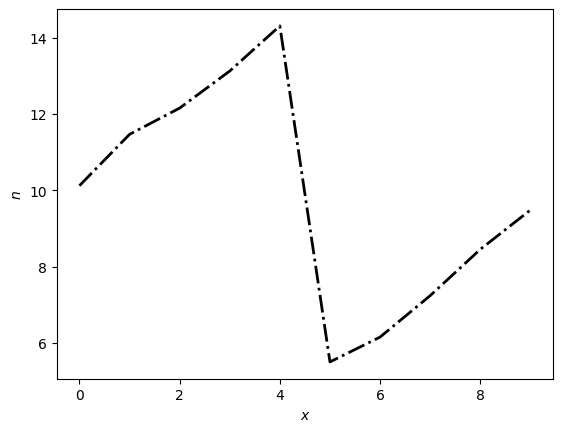

In [14]:
import matplotlib.pyplot as plt
x = range(len(density[0][:,0]))
y = density[0][:,0]
plt.plot(x, y, color='black', lw=2, ls='-.')
plt.xlabel('$x$')
plt.ylabel('$n$')

Bonus:
* $\texttt{color}$ = 
* $\texttt{lw}$ = 
* $\texttt{ls}$ = 

Because there is some noise in the data, not every cut will be identical, you can prove this by taking a cut in the $y$ direction 
> Plot a cut in the y direction

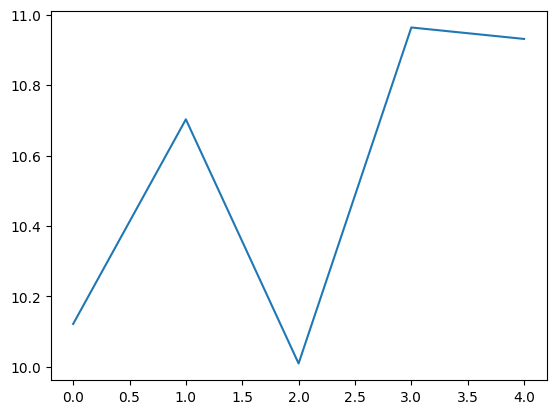

In [15]:
plt.plot(density[0][0])

If there is structure in both the $x$ and $y$ axes, it will be useful to see the whole field at once. There are a few ways of accomplishing this:
* matplotlib has a function for this purpose called $\texttt{imshow}$, that stands for image-show because image files like pngs are just arrays of numbers, like our data!

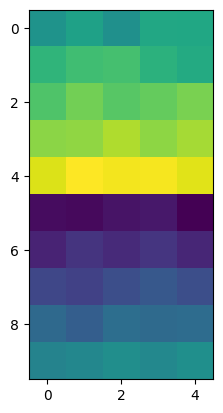

In [16]:
plt.imshow(density[0])

> Do you see anything out of the ordinary about this plot? Try to spot it before reading the next option!

* Because the first axis of the array is interpretted as x instead of y, things look rotated, plus the y-axis gets flipped from imshow (because of the way that image files are formatted) I made whats called a _convenience function_ or a _wrapper_, basically there is a way to get $\texttt{imshow}$ to do things the right way around, by giving it the keyword argument $\texttt{origin=`lower'}$, but its really annoying to rewrite that all the time, so I made my own version called $\texttt{show}$ that functions basically the same way, but formatting it in the way that I like. I put it in another package I made called $\texttt{kplot}$. Install that package, reload this notebook, and try the cell below!

(<Figure size 1000x1000 with 2 Axes>,
 <Axes: >,
 <matplotlib.collections.QuadMesh at 0x1187fb770>)

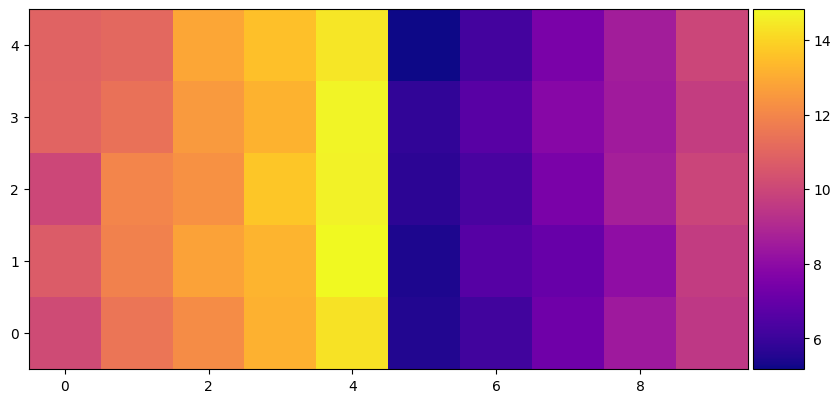

In [17]:
from kplot import show
show(density[0])

* finally, I also built a _method_ into the $\texttt{ScalarField}$ object. In python a method is just a function that is attached to a specific class/object. For example, strings have lots of useful methods, below is an example:

In [18]:
density_directory.upper()

'./SIMULATION/OUTPUTS/DENSITY'

whereas if upper were a regular function you would call it like:

In [19]:
upper(density_directory)

NameError: name 'upper' is not defined

To use the method version of my $\texttt{show}$ function, you just have to give it the timestep to show:

In [20]:
density.show(0)

AssertionError: 

## $\texttt{VectorField}$
---

A $\texttt{VectorField}$ is almost identical in function to a $\texttt{ScalarField}$, except to get a number from the Field you need to specify which component you want. Really, most of the time you will actually be interacting with $\texttt{ScalarField}$ objects, because each component of a $\texttt{VectorField}$ is itself a $\texttt{ScalarField}$.

In [3]:
from kgsim import VectorField
from kbasic import Folder
vf = Folder("./simulation/Output/B")
print(type(vf))
B = VectorField(vf, name="B")

<class 'kbasic.parsing.basic.Folder'>


TypeError: need a path or array-like object, but given (/Users/keyan/code/packages/kgsim/docs/tutorials/Fields/simulation/Output/B,)